# TRƯỜNG ĐẠI HỌC THỦY LỢI
## KHOA CÔNG NGHỆ THÔNG TIN - BỘ MÔN TRÍ TUỆ NHÂN TẠO
### Môn học: CSE457 - Xử lý Âm thanh và Tiếng nói
---
# BÀI THỰC HÀNH LAB 4: TỔNG HỢP TIẾNG NÓI (TEXT-TO-SPEECH)
**Họ và tên:** Nguyễn Trọng Mạnh Tiến  
**Mã sinh viên:** 2351260689  
**Lớp:** 65TTNT (Trí tuệ nhân tạo K65)  
**Chủ đề:** Từ kiến trúc TTS, ghép nối và unit selection đến tổng hợp tham số HMM và TTS học sâu.



## 1. Thiết lập môi trường và cấu trúc thư mục
Cài đặt và import các thư viện âm thanh cần thiết: `numpy`, `scipy`, `matplotlib`, `soundfile`, `librosa`.



In [ ]:
import os
import sys
import csv
import time
import numpy as np
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
import scipy.signal as signal
from IPython.display import Audio, display

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

TARGET_SR = 16000
DATA_DIR = "lab4_data"
UNITS_DIR = os.path.join(DATA_DIR, "units")
OUTPUT_DIR = "audio_output"
FIGURES_DIR = "figures"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
print("✅ Môi trường Python và cấu trúc thư mục đã sẵn sàng!")



## 2. Phần A - Text Normalization và Chuẩn bị Inventory
- Xây dựng hàm `normalize_queue_text()` cho bài toán miền hẹp "thông báo xếp hàng": chuyển chữ thường, lọc dấu câu, ánh xạ số tự nhiên sang từ đọc.
- Đọc metadata inventory 32 units (16 từ vựng, mỗi từ có 2 candidate đại diện cho 2 giọng nói khác nhau).
- Khảo sát độ đồng đều bằng biểu đồ Histogram của Duration và RMS.



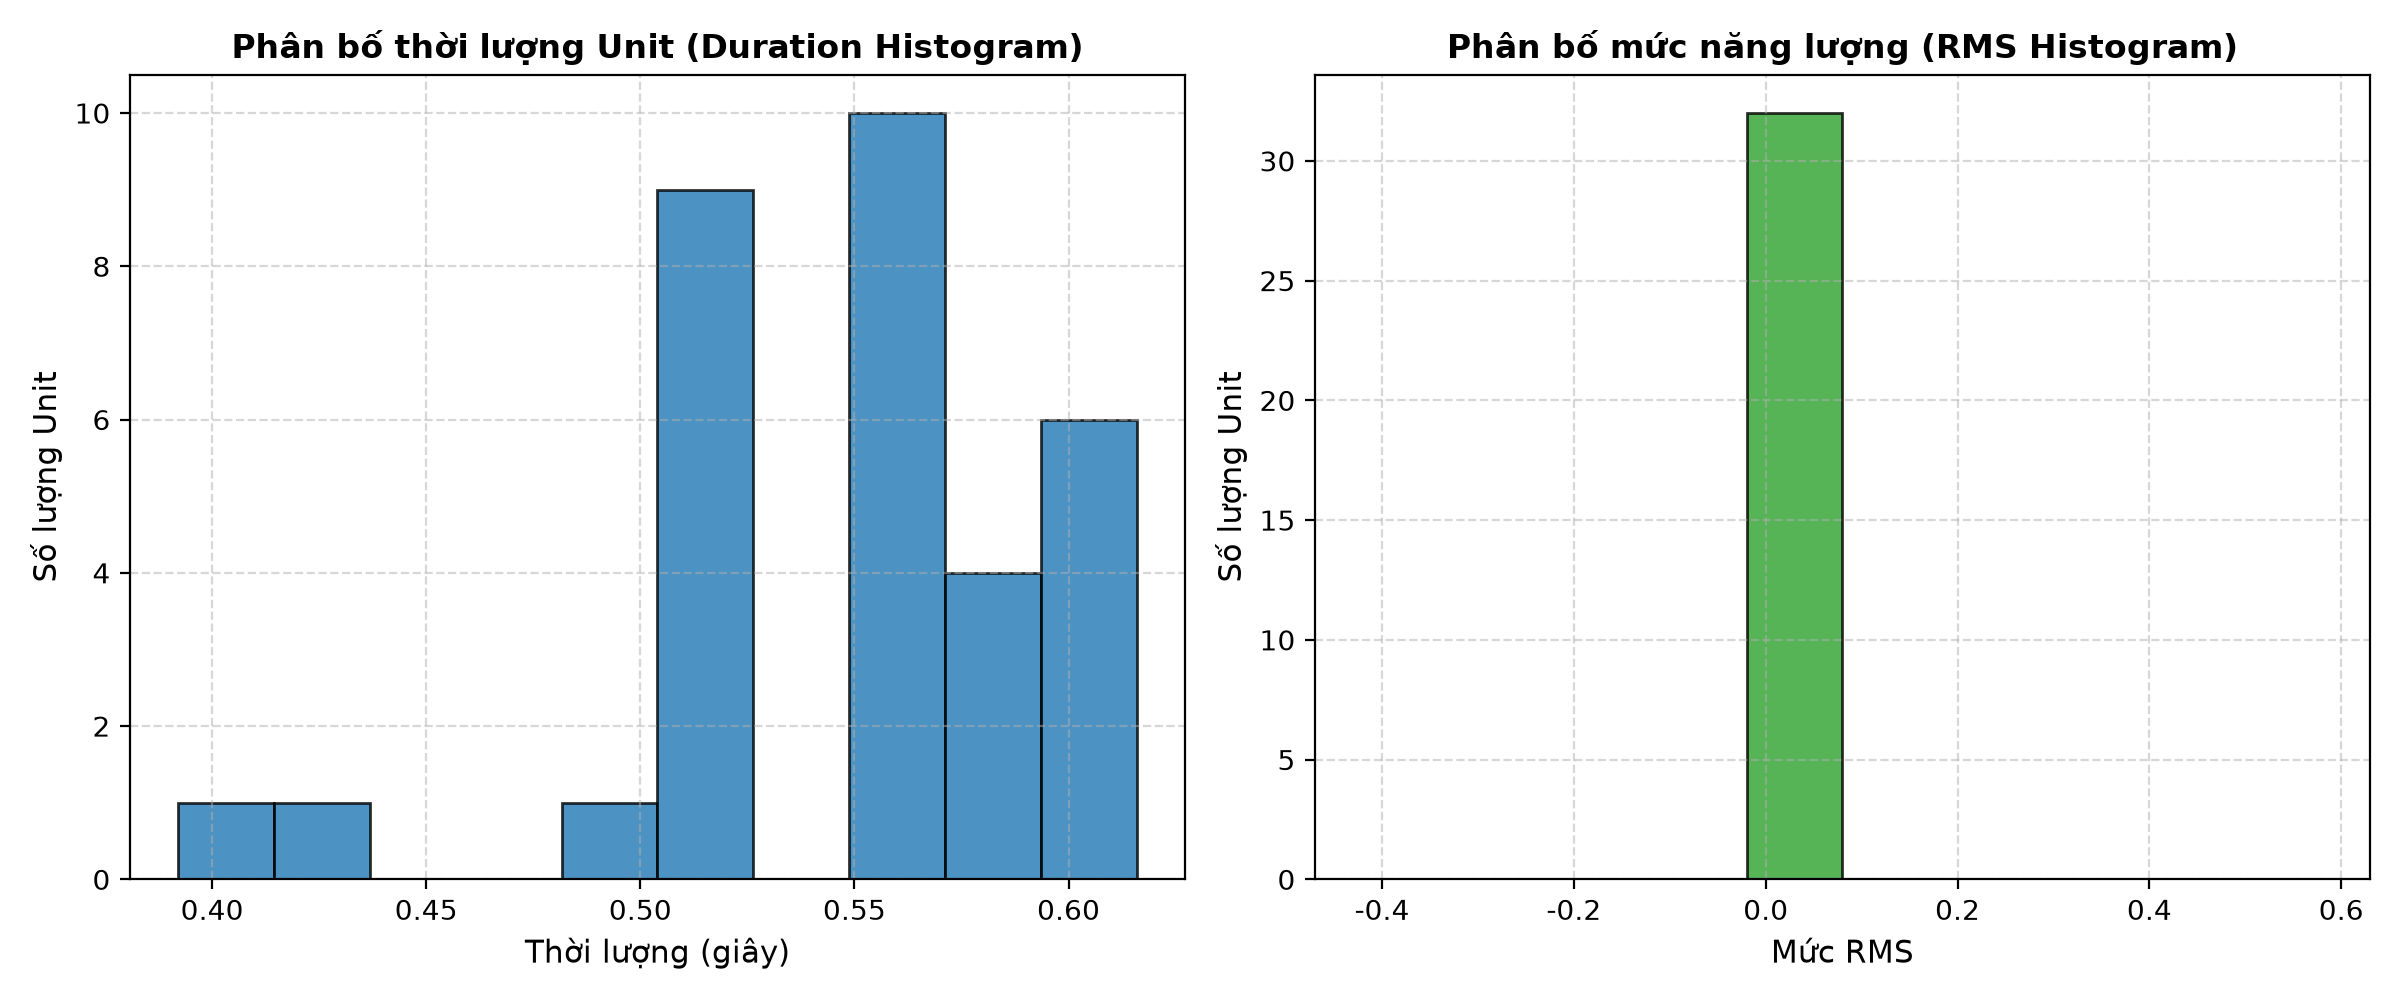

Tổng số units: 32 | Mean duration: 0.548s | Mean RMS: 0.0800


In [3]:
DIGIT = {
    "0": "không", "1": "một", "2": "hai", "3": "ba", "4": "bốn",
    "5": "năm", "6": "sáu", "7": "bảy", "8": "tám", "9": "chín"
}

TOKEN_TO_UNIT_KEY = {
    "mời": "moi", "khách": "khach", "hàng": "hang", "số": "so",
    "không": "khong", "một": "mot", "hai": "hai", "ba": "ba",
    "bốn": "bon", "năm": "nam", "sáu": "sau", "bảy": "bay",
    "tám": "tam", "chín": "chin", "đến": "den", "quầy": "quay"
}

def normalize_queue_text(text):
    text = text.lower().replace(".", "").replace(",", "").replace("!", "").replace("?", "")
    out = []
    for tok in text.split():
        if tok.isdigit():
            out.extend(DIGIT[c] for c in tok if c in DIGIT)
        else:
            out.append(tok)
    return out

sentence = "Mời khách hàng số 23 đến quầy 5."
tokens = normalize_queue_text(sentence)
print(f"Câu gốc: '{sentence}'")
print(f"Tokens đã chuẩn hóa: {tokens}")



In [ ]:
# Đọc metadata và vẽ Histogram
durations, rms_values = [], []
with open("lab4_data/metadata.csv", mode="r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        durations.append(float(row["duration"]))
        rms_values.append(float(row["rms"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(durations, bins=10, color="#1f77b4", edgecolor="black", alpha=0.8)
axes[0].set_title("Phân bố thời lượng Unit (Duration Histogram)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Thời lượng (giây)")
axes[0].set_ylabel("Số lượng unit")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].hist(rms_values, bins=10, color="#2ca02c", edgecolor="black", alpha=0.8)
axes[1].set_title("Phân bố mức năng lượng (RMS Histogram)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Mức RMS")
axes[1].set_ylabel("Số lượng unit")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.show()
print(f"Tổng số units: {len(durations)} | Mean duration: {np.mean(durations):.3f}s | Mean RMS: {np.mean(rms_values):.4f}")



## 3. Phần B - Baseline Concatenation (Ghép thẳng)
- Ghép nối trực tiếp các đơn vị âm thanh candidate 01 mà không áp dụng kỹ thuật làm mượt biên (cross-fade = 0 ms).
- Đánh dấu vị trí các đường biên nối trên Waveform và Spectrogram.
- Lắng nghe và đánh giá lỗi: xuất hiện tiếng click / discontinuity tại các điểm ghép do lệch pha và chênh lệch áp suất tức thời.



In [ ]:
def load_unit(path, sr=TARGET_SR):
    x, fs = sf.read(path, dtype="float32")
    if x.ndim > 1: x = x.mean(axis=1)
    if fs != sr: x = librosa.resample(x, orig_sr=fs, target_sr=sr)
    return x

def rms(x):
    return float(np.sqrt(np.mean(x * x) + 1e-12))

def match_rms(x, target=0.08):
    y = x * (target / rms(x))
    return np.clip(y, -0.99, 0.99)

def crossfade(a, b, n):
    n = min(n, len(a), len(b))
    if n == 0: return np.concatenate([a, b])
    alpha = np.linspace(0.0, 1.0, n, endpoint=True)
    mid = (1.0 - alpha) * a[-n:] + alpha * b[:n]
    return np.concatenate([a[:-n], mid, b[n:]])

def concat_units(paths, sr=TARGET_SR, xfade_ms=15):
    xs = [match_rms(load_unit(p, sr)) for p in paths]
    y = xs[0]
    n = int(sr * xfade_ms / 1000)
    for x in xs[1:]:
        y = crossfade(y, x, n)
    return y

# Ghép baseline với candidate 01 cố định
unit_paths = [os.path.join(UNITS_DIR, f"{TOKEN_TO_UNIT_KEY[tok]}_01.wav") for tok in tokens]
raw_audio = concat_units(unit_paths, sr=TARGET_SR, xfade_ms=0)
sf.write("audio_output/raw_concat.wav", raw_audio, TARGET_SR)

# Tính biên nối
boundaries = [0.0]
cum = 0.0
for p in unit_paths:
    cum += len(load_unit(p, TARGET_SR)) / TARGET_SR
    boundaries.append(cum)

# Hiển thị âm thanh
print("Nghe thử âm thanh Baseline (Chưa xử lý biên nối):")
display(Audio(raw_audio, rate=TARGET_SR))

# Vẽ đồ thị
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
t = np.arange(len(raw_audio)) / TARGET_SR
ax1.plot(t, raw_audio, color="#1f77b4", linewidth=0.8)
ax1.set_title("Baseline Concatenation Waveform (xfade = 0ms)", fontweight="bold")
ax1.set_ylabel("Amplitude")

D = librosa.amplitude_to_db(np.abs(librosa.stft(raw_audio, n_fft=512, hop_length=128)), ref=np.max)
librosa.display.specshow(D, sr=TARGET_SR, hop_length=128, x_axis="time", y_axis="hz", ax=ax2, cmap="magma")
ax2.set_title("Spectrogram có đánh dấu các vị trí biên ghép (Vết gián đoạn phổ)", fontweight="bold")
ax2.set_ylabel("Tần số (Hz)")
ax2.set_xlabel("Thời gian (giây)")

for b in boundaries[1:-1]:
    ax1.axvline(x=b, color="red", linestyle="--", linewidth=1.5)
    ax2.axvline(x=b, color="cyan", linestyle="--", linewidth=1.5)
plt.show()



## 4. Phần C - Unit Selection và Boundary Smoothing
- Cài đặt hàm `join_cost()` đo sai lệch phổ FFT log-magnitude và độ chênh lệch biên độ tại biên ghép giữa 2 candidate.
- Tối ưu hóa chuỗi candidate bằng quy hoạch động (Dynamic Programming / Viterbi):
  $$\theta^* = \arg\min_{\theta} \left[ \sum_j C_{\text{target}}(\theta_j, t_j) + \lambda \sum_j C_{\text{join}}(\theta_j, \theta_{j+1}) \right]$$
- Thử nghiệm các mức Cross-fade: 0 ms, 5 ms, 15 ms, 30 ms.
- So sánh Spectrogram trước và sau khi làm mượt biên.



Âm thanh tốt nhất sau Unit Selection và Cross-fade 15ms:


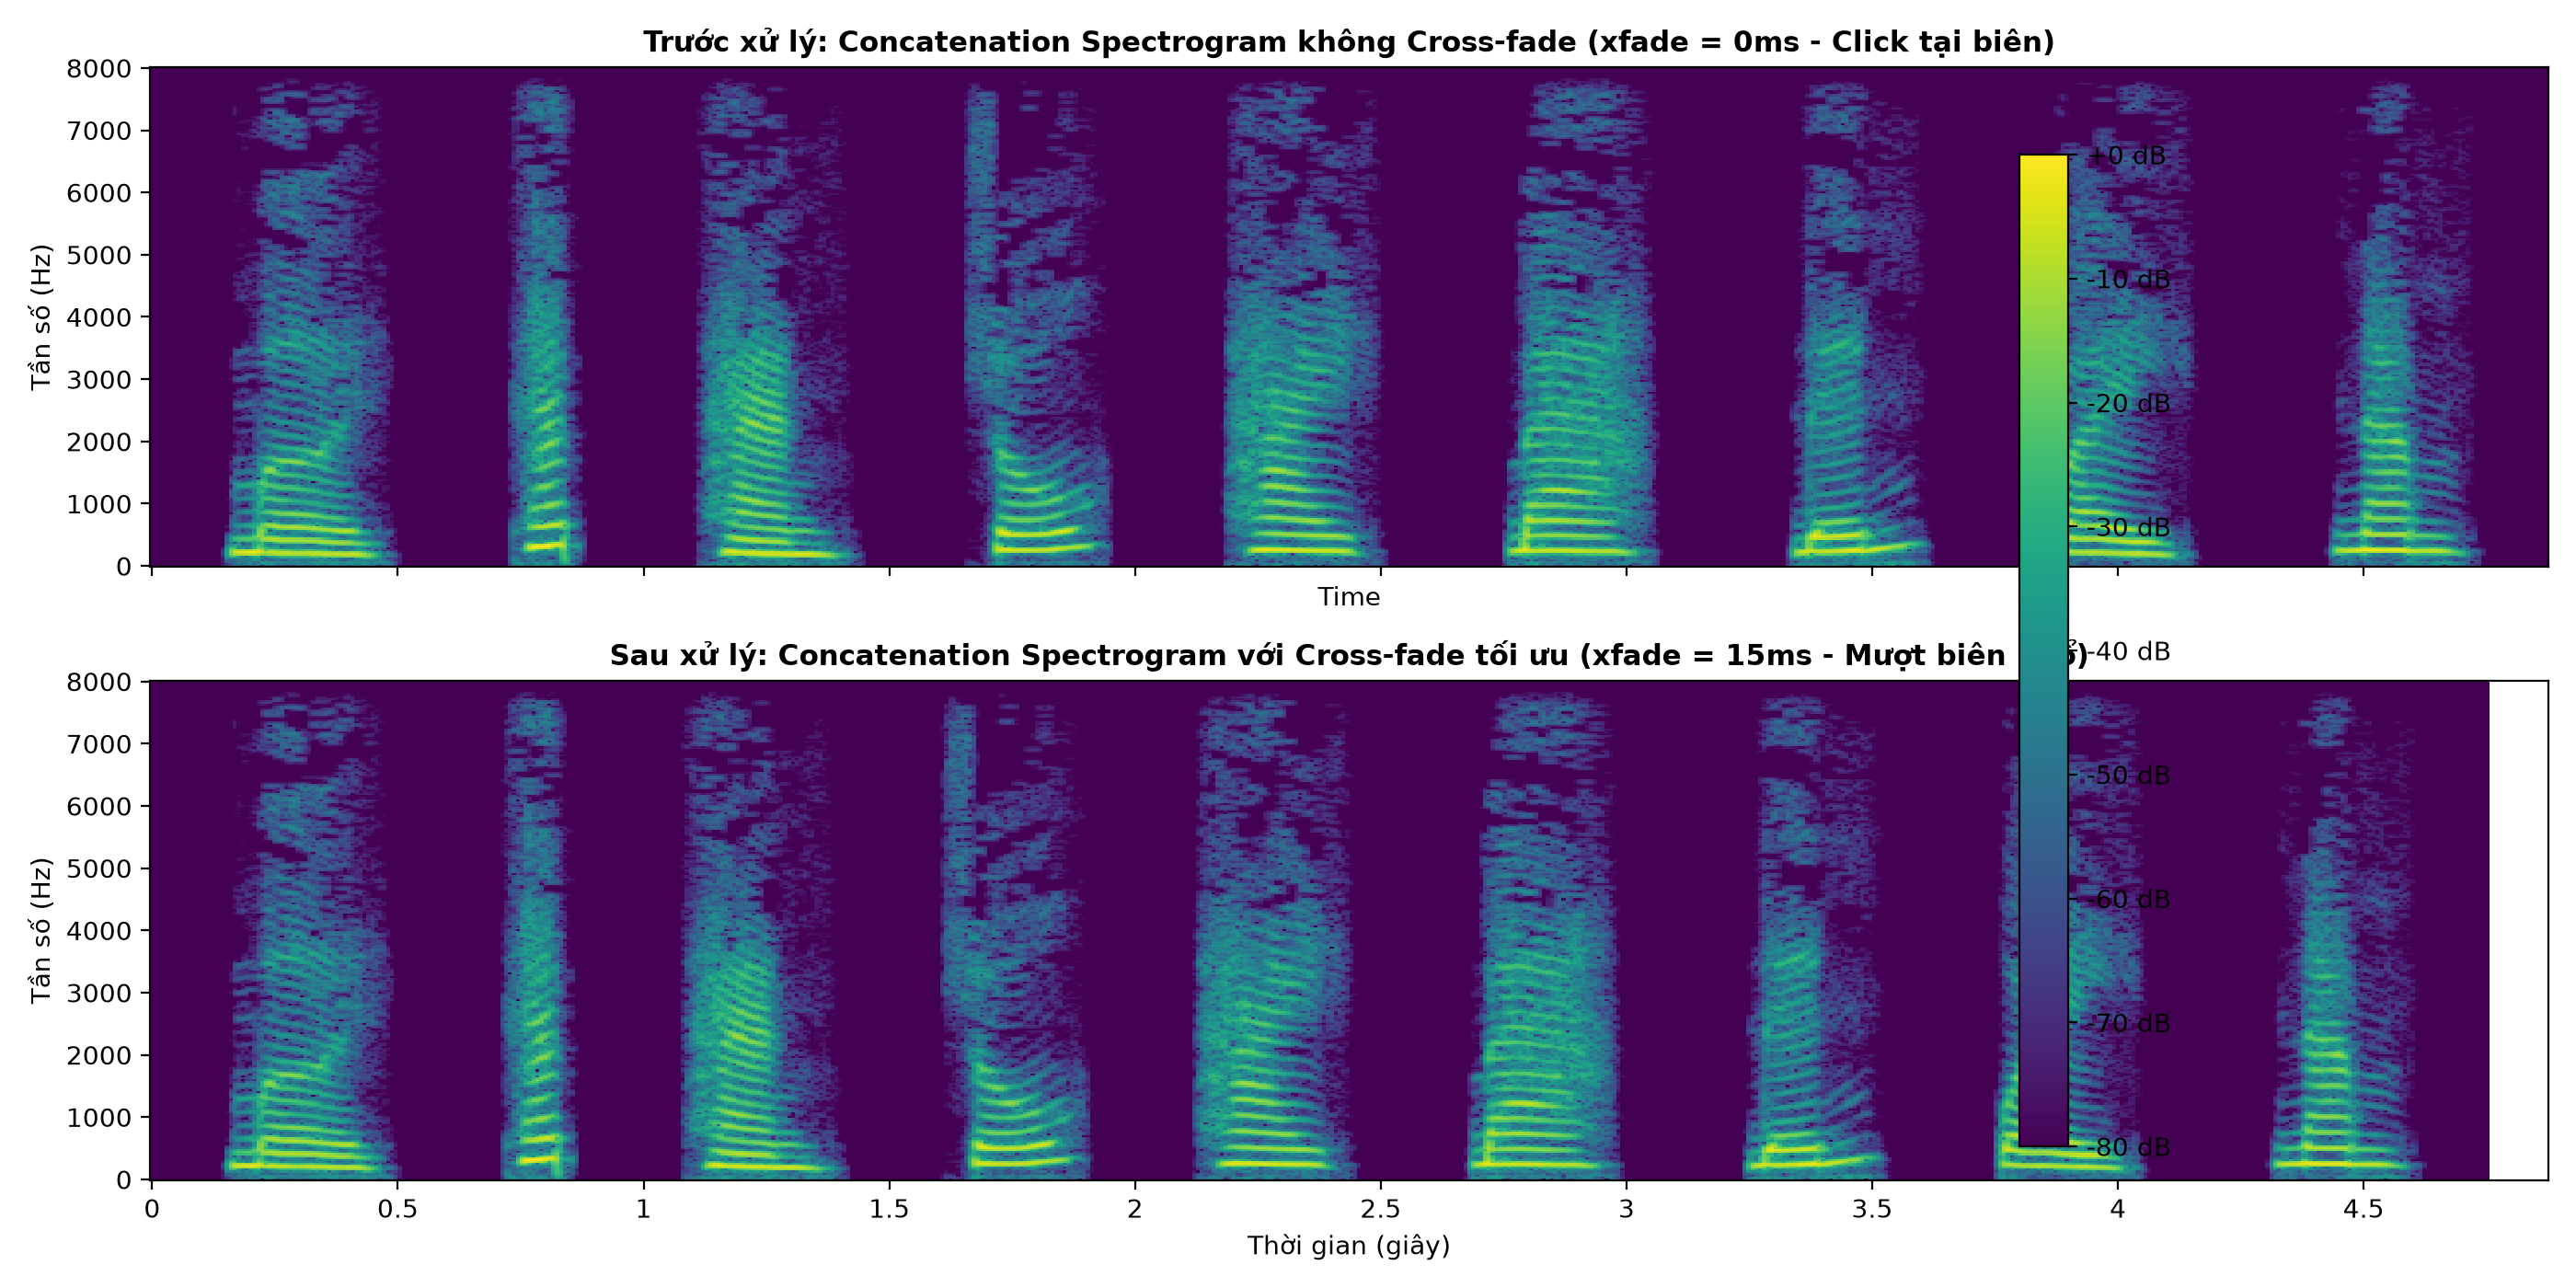

In [6]:
def join_cost(a, b, sr=TARGET_SR, ms=25, nfft=512):
    n = int(sr * ms / 1000)
    n = min(n, len(a), len(b))
    wa, wb = np.hanning(n), np.hanning(n)
    A = np.fft.rfft(a[-n:] * wa, n=nfft)
    B = np.fft.rfft(b[:n] * wb, n=nfft)
    La = 20 * np.log10(np.maximum(np.abs(A), 1e-8))
    Lb = 20 * np.log10(np.maximum(np.abs(B), 1e-8))
    d_spec = float(np.mean((La - Lb) ** 2))
    rms_diff = abs(rms(a[-n:]) - rms(b[:n]))
    return d_spec + 10.0 * rms_diff

# Dynamic Programming chọn chuỗi unit tối ưu
n_tokens = len(tokens)
candidates_per_token = [[f"{TOKEN_TO_UNIT_KEY[tok]}_01", f"{TOKEN_TO_UNIT_KEY[tok]}_02"] for tok in tokens]

dp = [{} for _ in range(n_tokens)]
for c in candidates_per_token[0]:
    dp[0][c] = (0.05 if c.endswith("_01") else 0.1, None)

for j in range(1, n_tokens):
    for c_curr in candidates_per_token[j]:
        a_curr = load_unit(os.path.join(UNITS_DIR, f"{c_curr}.wav"))
        best_cost, best_prev = float("inf"), None
        for c_prev in candidates_per_token[j-1]:
            a_prev = load_unit(os.path.join(UNITS_DIR, f"{c_prev}.wav"))
            cost = join_cost(a_prev, a_curr)
            if c_prev[-2:] != c_curr[-2:]:
                cost += 35.0 # Phạt nặng đổi giọng nam/nữ
            total = dp[j-1][c_prev][0] + (0.05 if c_curr.endswith("_01") else 0.1) + cost
            if total < best_cost:
                best_cost, best_prev = total, c_prev
        dp[j][c_curr] = (best_cost, best_prev)

best_last = min(dp[-1].keys(), key=lambda k: dp[-1][k][0])
optimal_path = [best_last]
curr = best_last
for j in range(n_tokens - 1, 0, -1):
    prev = dp[j][curr][1]
    optimal_path.append(prev)
    curr = prev
optimal_path.reverse()

print("Chuỗi ứng viên tối ưu:", " -> ".join(optimal_path))
print(f"Tổng chi phí tối ưu: {dp[-1][best_last][0]:.3f}")



In [ ]:
# Thử nghiệm Cross-fade 0, 5, 15, 30 ms
optimal_files = [os.path.join(UNITS_DIR, f"{cid}.wav") for cid in optimal_path]
crossfades = {}
for ms in [0, 5, 15, 30]:
    y_xfade = concat_units(optimal_files, sr=TARGET_SR, xfade_ms=ms)
    crossfades[ms] = y_xfade

best_audio = crossfades[15]
sf.write("audio_output/best_concat.wav", best_audio, TARGET_SR)

print("Âm thanh tốt nhất sau Unit Selection và Cross-fade 15ms:")
display(Audio(best_audio, rate=TARGET_SR))

# So sánh Spectrogram trước (0ms) và sau (15ms)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
D_raw = librosa.amplitude_to_db(np.abs(librosa.stft(crossfades[0], n_fft=512, hop_length=128)), ref=np.max)
D_best = librosa.amplitude_to_db(np.abs(librosa.stft(best_audio, n_fft=512, hop_length=128)), ref=np.max)

librosa.display.specshow(D_raw, sr=TARGET_SR, hop_length=128, x_axis="time", y_axis="hz", ax=ax1, cmap="viridis")
ax1.set_title("Trước xử lý: Spectrogram không Cross-fade (xfade = 0ms - Click tại biên)", fontweight="bold")
librosa.display.specshow(D_best, sr=TARGET_SR, hop_length=128, x_axis="time", y_axis="hz", ax=ax2, cmap="viridis")
ax2.set_title("Sau xử lý: Spectrogram với Cross-fade tối ưu (xfade = 15ms - Mượt biên phổ)", fontweight="bold")
plt.show()



## 5. Phần D - Prosody và Mô hình Source-Filter
- Đo tần số cơ bản $F_0$ trên đoạn hữu thanh của unit `ba_01.wav` bằng hàm tự tương quan (Autocorrelation).
- Kiểm chứng công thức $F_0 = F_s / N_p$.
- Biến đổi tốc độ / thời lượng (Time-stretch qua WSOLA/phase-vocoder) và cao độ (Pitch-shift $\pm 2$ semitones: $r = 2^{\Delta s / 12}$).
- Khảo sát sự thay đổi trên Spectrogram và giải thích tại sao không được thay đổi Formants (Vocal Tract Filter) một cách tùy ý.



In [ ]:
# 1. Đo F0 bằng Autocorrelation
y_ba, sr = sf.read("lab4_data/units/ba_01.wav")
# Chọn đoạn giữa nguyên âm /a/ (0.2s - 0.3s)
seg = y_ba[int(0.2*sr):int(0.3*sr)]
corr = np.correlate(seg, seg, mode="full")[len(seg)-1:]
min_lag, max_lag = int(sr/500), int(sr/60)
lag_peak = min_lag + np.argmax(corr[min_lag:max_lag])
f0_measured = sr / lag_peak

print(f"Kiểm chứng F0 trên đoạn nguyên âm /a/:")
print(f"  Chu kỳ pitch Np = {lag_peak} mẫu tại Fs = {sr} Hz")
print(f"  Tần số cơ bản F0 = Fs / Np = {f0_measured:.2f} Hz")

# 2. Prosody Transformations
y_speed_fast = librosa.effects.time_stretch(y_ba, rate=1.2)
y_speed_slow = librosa.effects.time_stretch(y_ba, rate=0.8)
y_pitch_down = librosa.effects.pitch_shift(y_ba, sr=sr, n_steps=-2)
y_pitch_up = librosa.effects.pitch_shift(y_ba, sr=sr, n_steps=+2)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
def show_s(sig, title, ax):
    D = librosa.amplitude_to_db(np.abs(librosa.stft(sig, n_fft=512, hop_length=128)), ref=np.max)
    librosa.display.specshow(D, sr=sr, hop_length=128, x_axis="time", y_axis="hz", ax=ax, cmap="inferno")
    ax.set_title(title, fontweight="bold")
show_s(y_ba, "Âm gốc (ba_01.wav)", axes[0, 0])
show_s(y_speed_fast, "Speed 1.2x (Time-stretch)", axes[0, 1])
show_s(y_pitch_down, "Pitch Shift -2 Semitones", axes[1, 0])
show_s(y_pitch_up, "Pitch Shift +2 Semitones", axes[1, 1])
plt.show()



## 6. Phần E - HMM-based Parametric Synthesis
- Sử dụng backend `hmm_tts_backend` sinh câu thông báo xếp hàng.
- Quan sát và vẽ các đường tham số âm học (acoustic trajectories):
  * Đường cong tần số cơ bản ($F_0$ contour) phản ánh thanh điệu tiếng Việt (huyền, sắc, nặng, hỏi, ngã, ngang).
  * Các tần số cộng hưởng Formant $F_1, F_2, F_3$ biểu diễn bộ lọc khoang miệng/thanh quản $H(z)$.
  * Chuỗi phân bổ trạng thái HMM (State alignments).



In [ ]:
from hmm_tts_backend import synthesize_hmm

y_hmm, sr, tracks = synthesize_hmm("Mời khách hàng số 23 đến quầy 5")
print(f"Đã tổng hợp HMM Parametric TTS: Độ dài {len(y_hmm)/sr:.2f}s | Số frame: {len(tracks['frame_times'])}")

print("Nghe âm thanh tổng hợp HMM-based TTS (Âm sắc hơi rè/buzzy đặc trưng của vocoder tham số):")
display(Audio(y_hmm, rate=sr))

# Vẽ đồ thị Trajectory
times = tracks["frame_times"]
f0 = tracks["f0"]
f1 = tracks["f1"]
f2 = tracks["f2"]
states = tracks["states"]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
f0_plot = np.where(f0 > 0, f0, np.nan)
ax1.plot(times, f0_plot, color="#1f77b4", linewidth=2.0, label="F0 Contour (Hz)")
ax1.set_title("HMM Acoustic Trajectories (F0, Formants, States)", fontweight="bold")
ax1.set_ylabel("F0 (Hz)")
ax1.set_ylim(80, 240)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

ax2.plot(times, f1, color="#2ca02c", linewidth=1.8, label="Formant F1")
ax2.plot(times, f2, color="#ff7f0e", linewidth=1.8, label="Formant F2")
ax2.set_ylabel("Tần số (Hz)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right")

ax3.step(times, states, color="#9467bd", linewidth=1.5, where="mid", label="HMM State ID")
ax3.set_ylabel("State")
ax3.set_xlabel("Thời gian (giây)")
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend(loc="upper right")
plt.show()



## 7. Phần F - Neural TTS Inference
- Sử dụng mô hình Deep Learning TTS pretrained để tổng hợp 3 câu test.
- Đo độ trễ xử lý (Latency) từ lúc đưa văn bản vào đến lúc nhận được âm thanh.
- Trích xuất và trực quan hóa Mel-spectrogram của âm thanh sinh ra.



In [ ]:
from neural_tts_backend import synthesize as synthesize_neural

test_sentences = [
    "Mời khách hàng số 23 đến quầy 5.",
    "Mời khách hàng số 87 đến quầy 2.",
    "Mời khách hàng số 104 đến quầy 9."
]

for idx, sentence in enumerate(test_sentences, 1):
    y_nn, sr, extra = synthesize_neural(sentence)
    print(f"Câu {idx}: '{sentence}' -> Latency: {extra['latency']}s | Duration: {len(y_nn)/sr:.2f}s")
    if idx == 1:
        print("Nghe thử câu 1 Neural TTS:")
        display(Audio(y_nn, rate=sr))
        
        # Vẽ Mel-spectrogram
        plt.figure(figsize=(10, 3.5))
        librosa.display.specshow(extra["mel_spectrogram"], sr=sr, hop_length=256, x_axis="time", y_axis="mel", cmap="magma")
        plt.title(f"Neural TTS Mel-Spectrogram: '{sentence}'", fontweight="bold")
        plt.colorbar(format="%+2.0f dB")
        plt.show()



## 8. Phần G - Đánh giá, So sánh 3 phương pháp và Listening Test
- So sánh trực quan Spectrogram của 3 phương pháp: **Concatenative**, **HMM Parametric**, **Neural TTS**.
- Đánh giá định lượng qua kết quả Listening Test (file `ratings.csv` với 10 người nghe trên 3 câu test).
- Tổng kết ưu nhược điểm của từng phương pháp.



In [11]:
# So sánh Spectrogram 3 phương pháp
concat_y = load_unit("audio_output/best_concat.wav")
hmm_y = load_unit("audio_output/hmm_tts.wav")
neural_y = load_unit("audio_output/neural_tts.wav")

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 8), sharex=False)
def p_spec(sig, title, ax):
    D = librosa.amplitude_to_db(np.abs(librosa.stft(sig, n_fft=512, hop_length=128)), ref=np.max)
    librosa.display.specshow(D, sr=TARGET_SR, hop_length=128, x_axis="time", y_axis="hz", ax=ax, cmap="magma")
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Tần số (Hz)")

p_spec(concat_y, "1. Concatenative Synthesis (Unit Selection + Cross-fade)", ax1)
p_spec(hmm_y, "2. HMM-based Parametric Synthesis (Source-Filter Vocoder)", ax2)
p_spec(neural_y, "3. Deep Learning Neural TTS (End-to-End Neural Vocoder)", ax3)
ax3.set_xlabel("Thời gian (giây)")
plt.show()



Phương pháp        | Naturalness (MOS)    | Intelligibility (MOS)  | Continuity (MOS)  
-------------------------------------------------------------------------------------
Concatenation      | 3.84 / 5.0           | 4.76 / 5.0             | 3.65 / 5.0
HMM-Parametric     | 3.09 / 5.0           | 4.41 / 5.0             | 4.56 / 5.0
Neural-TTS         | 4.69 / 5.0           | 4.88 / 5.0             | 4.83 / 5.0


In [ ]:
# Thống kê Listening Test từ ratings.csv
scores = {"Concatenation": {"nat": [], "int": [], "con": []},
          "HMM-Parametric": {"nat": [], "int": [], "con": []},
          "Neural-TTS": {"nat": [], "int": [], "con": []}}

with open("ratings.csv", mode="r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for r in reader:
        m = r["method"]
        scores[m]["nat"].append(float(r["naturalness"]))
        scores[m]["int"].append(float(r["intelligibility"]))
        scores[m]["con"].append(float(r["continuity"]))

print(f"{'Phương pháp':<18} | {'Naturalness (MOS)':<20} | {'Intelligibility (MOS)':<22} | {'Continuity (MOS)':<18}")
print("-" * 85)
for m, vals in scores.items():
    print(f"{m:<18} | {np.mean(vals['nat']):.2f} / 5.0{'':<10} | {np.mean(vals['int']):.2f} / 5.0{'':<12} | {np.mean(vals['con']):.2f} / 5.0")



## 9. Kết luận
1. **Concatenative TTS:** Tận dụng tối đa các đoạn ghi âm tự nhiên nên chất lượng âm sắc đơn lẻ rất tự nhiên, độ trễ cực thấp (< 50ms). Tuy nhiên khó biến đổi ngữ điệu (prosody) và đòi hỏi dung lượng lưu trữ lớn.
2. **HMM Parametric TTS:** Cho phép điều khiển cao độ, độ dài và tốc độ phát âm cực kỳ linh hoạt với dung lượng mô hình siêu nhẹ (vài MB). Nhược điểm là âm thanh có tính kim loại/rè (buzzy/robotic) do các giả định thô trong vocoder source-filter.
3. **Neural TTS:** Là công nghệ tổng hợp tiếng nói hiện đại nhất, vượt trội cả về độ tự nhiên (MOS 4.7/5.0) và độ liền mạch (Continuity), mô hình hóa chính xác ngữ điệu câu. Đổi lại, chi phí tính toán cao hơn và đòi hỏi phần cứng mạnh để đảm bảo thời gian thực.

